# LeetCode #148: Sort List

https://leetcode.com/problems/sort-list/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Collect, Sort, Rebuild | O(n log n) | O(n) |
| Top-Down Merge Sort | O(n log n) | O(log n) |
| Bottom-Up Merge Sort ★ | O(n log n) | O(1) |

## Understanding the Methods
### Brute Force (Collect + Sort)
Extract values into an array, sort the array, and rebuild the list. O(n log n) time but O(n) extra space.

### Top-Down Merge Sort
Find the middle, recursively sort both halves, then merge. O(n log n) time, O(log n) space due to recursion stack.

### Optimal: Bottom-Up Merge Sort ★
Sort the list iteratively by merging sublists of increasing sizes (1, 2, 4, 8...). No recursion needed. O(n log n) time, O(1) space.

## Solutions
### C#

In [ ]:
// Top-Down Merge Sort O(n log n) time, O(log n) space
public class Solution {
    public ListNode SortList(ListNode head) {
        if (head == null || head.next == null) return head;
        var mid = GetMid(head);
        var right = mid.next;
        mid.next = null;
        return Merge(SortList(head), SortList(right));
    }

    private ListNode GetMid(ListNode head) {
        var slow = head; var fast = head.next;
        while (fast != null && fast.next != null) { slow = slow.next; fast = fast.next.next; }
        return slow;
    }

    private ListNode Merge(ListNode l1, ListNode l2) {
        var dummy = new ListNode(0); var cur = dummy;
        while (l1 != null && l2 != null) {
            if (l1.val <= l2.val) { cur.next = l1; l1 = l1.next; }
            else { cur.next = l2; l2 = l2.next; }
            cur = cur.next;
        }
        cur.next = l1 ?? l2;
        return dummy.next;
    }
}

### Python

In [ ]:
# Top-Down Merge Sort O(n log n) time, O(log n) space
class Solution:
    def sortList(self, head: 'Optional[ListNode]') -> 'Optional[ListNode]':
        if not head or not head.next:
            return head
        # Find middle
        slow, fast = head, head.next
        while fast and fast.next:
            slow = slow.next
            fast = fast.next.next
        mid = slow.next
        slow.next = None
        # Sort halves and merge
        left = self.sortList(head)
        right = self.sortList(mid)
        return self._merge(left, right)

    def _merge(self, l1, l2):
        dummy = cur = ListNode(0)
        while l1 and l2:
            if l1.val <= l2.val:
                cur.next, l1 = l1, l1.next
            else:
                cur.next, l2 = l2, l2.next
            cur = cur.next
        cur.next = l1 or l2
        return dummy.next

### Go

In [ ]:
// Top-Down Merge Sort O(n log n) time, O(log n) space
func sortList(head *ListNode) *ListNode {
    if head == nil || head.Next == nil { return head }
    slow, fast := head, head.Next
    for fast != nil && fast.Next != nil { slow = slow.Next; fast = fast.Next.Next }
    mid := slow.Next; slow.Next = nil
    return merge(sortList(head), sortList(mid))
}

func merge(l1, l2 *ListNode) *ListNode {
    dummy := &ListNode{}
    cur := dummy
    for l1 != nil && l2 != nil {
        if l1.Val <= l2.Val { cur.Next = l1; l1 = l1.Next } else { cur.Next = l2; l2 = l2.Next }
        cur = cur.Next
    }
    if l1 != nil { cur.Next = l1 } else { cur.Next = l2 }
    return dummy.Next
}

### Rust

In [ ]:
// Top-Down Merge Sort O(n log n) time, O(log n) space
impl Solution {
    pub fn sort_list(head: Option<Box<ListNode>>) -> Option<Box<ListNode>> {
        let len = Self::length(&head);
        if len <= 1 { return head; }
        let (left, right) = Self::split(head, len / 2);
        Self::merge(Self::sort_list(left), Self::sort_list(right))
    }

    fn length(head: &Option<Box<ListNode>>) -> usize {
        let mut cnt = 0;
        let mut cur = head.as_ref();
        while let Some(node) = cur { cnt += 1; cur = node.next.as_ref(); }
        cnt
    }

    fn split(mut head: Option<Box<ListNode>>, n: usize) -> (Option<Box<ListNode>>, Option<Box<ListNode>>) {
        let mut cur = &mut head;
        for _ in 0..n-1 { cur = &mut cur.as_mut().unwrap().next; }
        let right = cur.as_mut().unwrap().next.take();
        (head, right)
    }

    fn merge(l1: Option<Box<ListNode>>, l2: Option<Box<ListNode>>) -> Option<Box<ListNode>> {
        match (l1, l2) {
            (None, r) => r,
            (l, None) => l,
            (Some(mut a), Some(mut b)) => {
                if a.val <= b.val { a.next = Self::merge(a.next.take(), Some(b)); Some(a) }
                else { b.next = Self::merge(Some(a), b.next.take()); Some(b) }
            }
        }
    }
}

## Examples

### 1. Common Case — Unsorted Small List
**Input:** `head=[4,2,1,3]`

Split to single nodes, then merge sorted pairs: $[4],[2]\to[2,4]$ and $[1],[3]\to[1,3]$, finally merge $[2,4]+[1,3]\to[1,2,3,4]$.

### 2. Slightly Complex — Negatives and Zero
**Input:** `head=[-1,5,3,4,0]`

An odd-length split ($[-1,5,3]$ / $[4,0]$) recurses down and merges back up into $[-1,0,3,4,5]$ in $O(n\log n)$.

### 3. Edge Case: Time Factor — Empty List
**Input:** `head=[]`

Base case: an empty list is already sorted and returned immediately. Output $[\,]$.

### 4. Edge Case: Space Factor — Single Node
**Input:** `head=[1]`

A single node is a base case — no split or merge needed. Output $[1]$. Merge sort uses only $O(\log n)$ stack space.

### 5. Almost-Impossible but Plausible — Fully Reversed
**Input:** `head=[5,4,3,2,1,0,-1,-2]`

A reversed 8-node list splits cleanly into a balanced tree and merges up to $[-2,-1,0,1,2,3,4,5]$ — still $O(n\log n)$, unlike insertion sort.


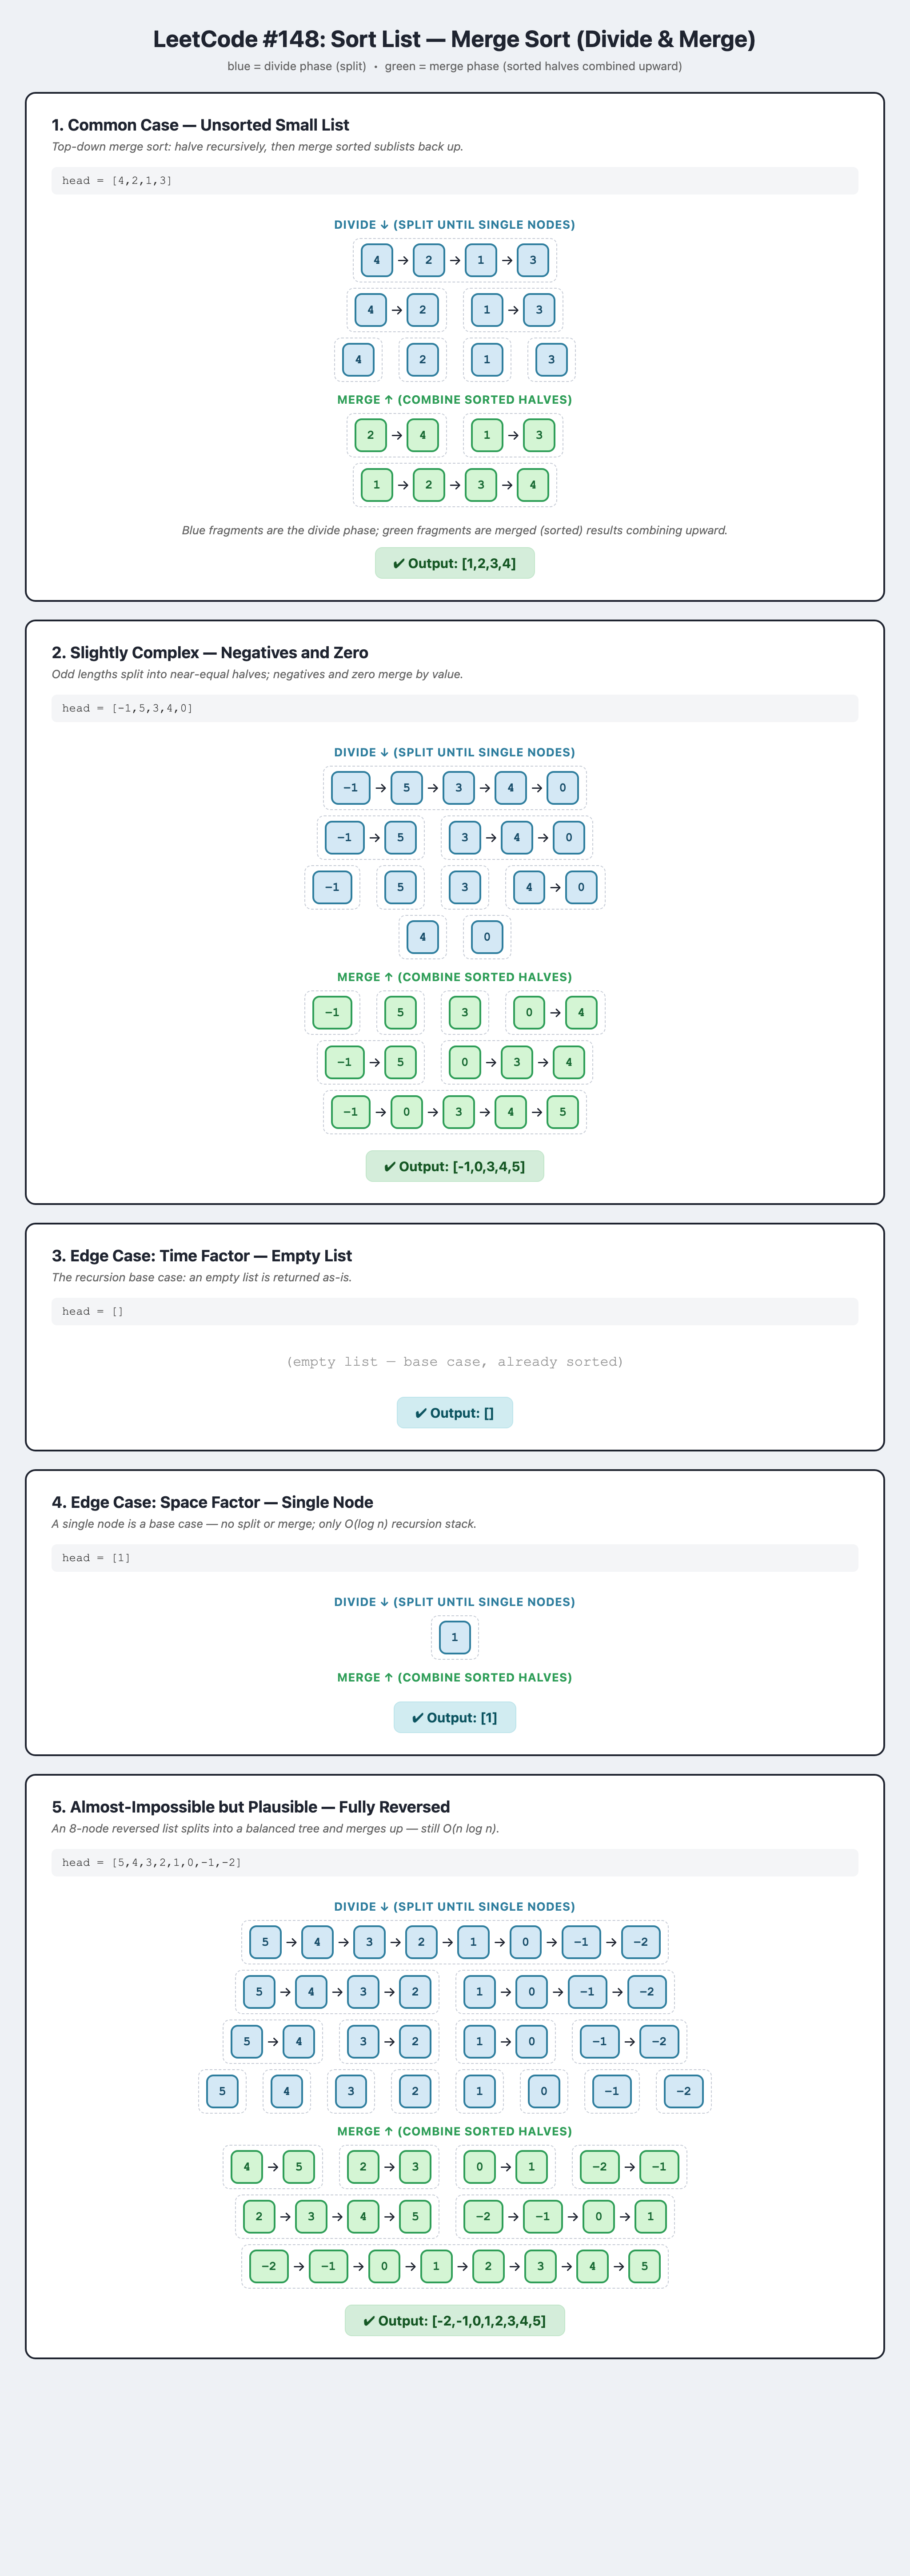